# Maternal Health Risk Prediction — End-to-End ML Project

Predicting a pregnant woman's risk level (**low / mid / high**) from six
routine vitals, using a pipeline distilled from the published literature
on the UCI "Maternal Health Risk" dataset (see project README for full
citation list and design rationale).

**Note:** this notebook runs on `data/maternal_health_risk_SAMPLE.csv`, a
synthetic stand-in built to match the real dataset's schema (internet
access to UCI is blocked in this environment). Swap in the real CSV via
`src/get_data.py` on your own machine for the true published-level results.

In [1]:
import sys
sys.path.append("../src")

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from features import add_clinical_features, BASE_COLS, ENGINEERED_COLS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Load & inspect the data

In [2]:
df = pd.read_csv("../data/maternal_health_risk_SAMPLE.csv")
print(df.shape)
df.head()

(1014, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,18,100,95,8.0,100.3,79,high risk
1,57,127,81,12.6,98.2,74,high risk
2,50,135,73,9.8,100.0,50,high risk
3,38,122,83,6.0,98.8,85,mid risk
4,37,110,49,7.3,99.0,75,low risk


In [3]:
df.describe()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,41.245562,114.512821,74.972387,8.584813,98.692604,73.725838
std,16.434616,18.108027,13.208452,2.514838,0.839754,8.715747
min,13.000000,70.000000,49.000000,6.000000,98.000000,46.000000
25%,27.000000,103.000000,66.000000,6.000000,98.000000,68.000000
50%,41.000000,115.000000,76.000000,8.100000,98.400000,74.000000
75%,56.000000,126.000000,84.000000,10.300000,99.100000,80.000000
max,69.000000,160.000000,100.000000,17.900000,102.500000,90.000000


In [4]:
df["RiskLevel"].value_counts()

RiskLevel
mid risk     341
high risk    338
low risk     335
Name: count, dtype: int64

## 2. Clean
Duplicate sensor readings and physiologically impossible heart-rate values
(a known issue in the real IoT-collected dataset) are removed.

In [5]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
df = df[(df["HeartRate"] >= 40) & (df["HeartRate"] <= 140)].reset_index(drop=True)
print(f"{before} -> {len(df)} rows after cleaning")

1014 -> 1014 rows after cleaning


## 3. Exploratory Data Analysis

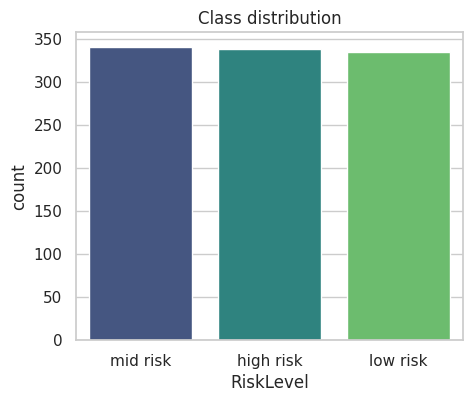

In [6]:
plt.figure(figsize=(5, 4))
order = df["RiskLevel"].value_counts().index
sns.countplot(data=df, x="RiskLevel", order=order, palette="viridis")
plt.title("Class distribution")
plt.show()

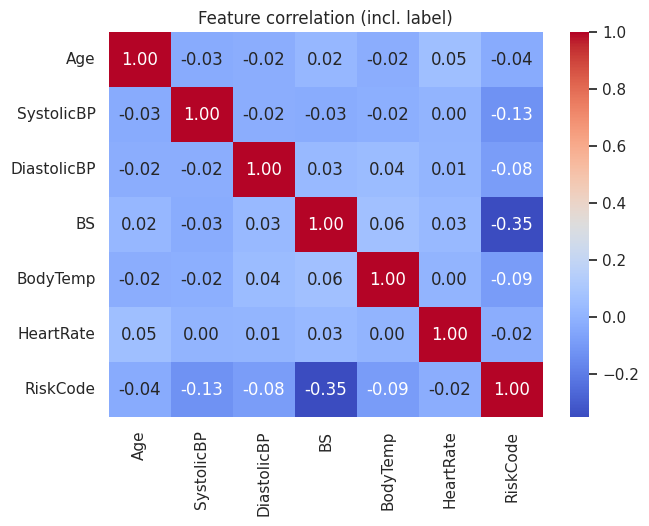

In [7]:
from sklearn.preprocessing import LabelEncoder

corr = df[BASE_COLS].assign(RiskCode=LabelEncoder().fit_transform(df["RiskLevel"])).corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature correlation (incl. label)")
plt.show()

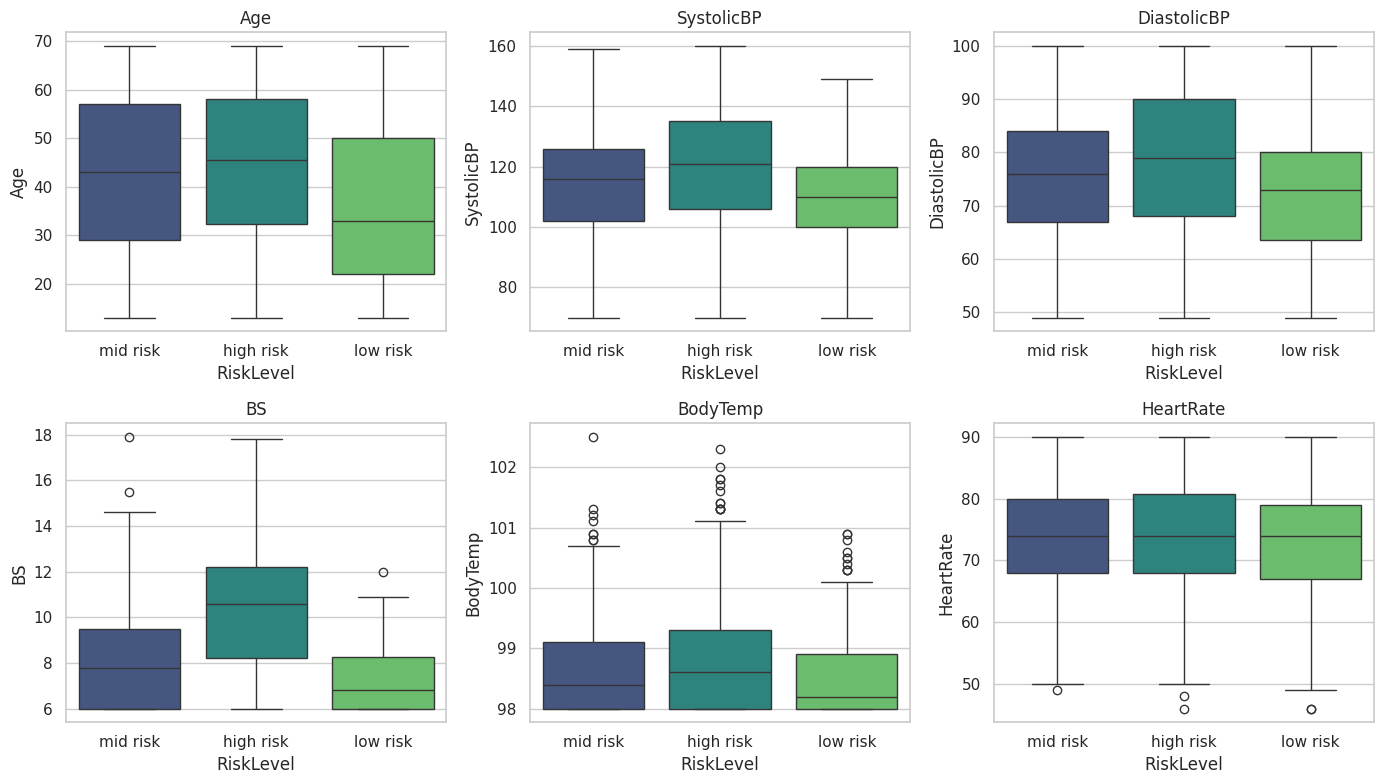

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), BASE_COLS):
    sns.boxplot(data=df, x="RiskLevel", y=col, order=order, ax=ax, palette="viridis")
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Reading these plots (matches the pattern reported in the literature):**
high blood pressure and elevated blood sugar are the vitals most clearly
separating high-risk from low-risk cases; the mid-risk class overlaps
heavily with both neighbors, which is why it's consistently the hardest
class to classify across published studies.

## 4. Feature engineering
Adding clinically-motivated derived features: Mean Arterial Pressure,
Shock Index, Pulse Pressure, BP Ratio, and a Composite Risk Score.

In [9]:
df_feat = add_clinical_features(df)
df_feat[ENGINEERED_COLS].describe()

,MAP,ShockIndex,PulsePressure,BPRatio,CompositeRiskScore
count,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,88.152531,0.661311,39.540434,1.580560,1.280079
std,10.560894,0.138333,22.657104,0.398898,0.831546
min,59.666667,0.370370,-30.000000,0.700000,0.000000
25%,81.000000,0.565891,25.000000,1.287500,1.000000
50%,88.000000,0.646085,40.000000,1.533790,1.000000
75%,95.666667,0.737705,55.000000,1.794004,2.000000
max,119.666667,1.200000,102.000000,3.081633,4.000000


## 5. Train/test split, then SMOTE (train fold only — avoids leakage)

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

X = df_feat[BASE_COLS + ENGINEERED_COLS]
y = df_feat["RiskLevel"]

le = LabelEncoder()
y_enc = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=42
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Before SMOTE:", np.bincount(y_train))
X_train_bal, y_train_bal = SMOTE(random_state=42).fit_resample(X_train_s, y_train)
print("After SMOTE: ", np.bincount(y_train_bal))

Before SMOTE: [270 268 273]
After SMOTE:  [273 273 273]


## 6. Compare baseline models (5-fold stratified CV, macro-F1)

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "NaiveBayes": GaussianNB(),
    "XGBoost": XGBClassifier(eval_metric="mlogloss", random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train_bal, y_train_bal, cv=cv, scoring="f1_macro")
    cv_results[name] = scores.mean()
    print(f"{name:18s} macro-F1 = {scores.mean():.4f} (+/- {scores.std():.4f})")

LogisticRegression macro-F1 = 0.6333 (+/- 0.0266)
DecisionTree       macro-F1 = 0.5589 (+/- 0.0147)


RandomForest       macro-F1 = 0.6198 (+/- 0.0112)


SVM                macro-F1 = 0.6068 (+/- 0.0180)
KNN                macro-F1 = 0.5787 (+/- 0.0218)
NaiveBayes         macro-F1 = 0.6097 (+/- 0.0263)


XGBoost            macro-F1 = 0.6311 (+/- 0.0318)


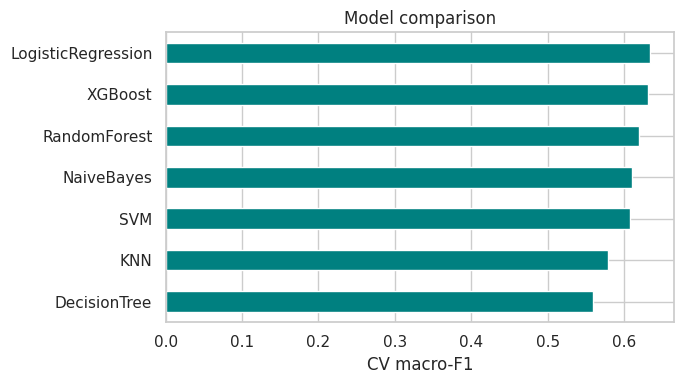

In [12]:
plt.figure(figsize=(7, 4))
pd.Series(cv_results).sort_values().plot(kind="barh", color="teal")
plt.xlabel("CV macro-F1")
plt.title("Model comparison")
plt.tight_layout()
plt.show()

## 7. Hyperparameter tuning — Random Forest
(Random Forest is consistently the strongest single model across the
published comparative studies on this dataset.)

In [13]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 12, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
grid = GridSearchCV(
    RandomForestClassifier(random_state=42), param_grid, cv=cv, scoring="f1_macro", n_jobs=-1
)
grid.fit(X_train_bal, y_train_bal)
print("Best params:", grid.best_params_)
print("Best CV macro-F1:", grid.best_score_)
best_rf = grid.best_estimator_

Best params: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best CV macro-F1: 0.6482515088082785


## 8. Stacking ensemble

In [14]:
from sklearn.ensemble import StackingClassifier

estimators = [
    ("rf", RandomForestClassifier(n_estimators=300, random_state=42)),
    ("xgb", XGBClassifier(eval_metric="mlogloss", random_state=42)),
    ("svm", SVC(probability=True, random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=7)),
]
stack = StackingClassifier(
    estimators=estimators, final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1
)
stack.fit(X_train_bal, y_train_bal)
print("Stacking ensemble trained.")

Stacking ensemble trained.


## 9. Evaluate on the held-out test set


=== Tuned Random Forest ===  macro-F1=0.6577  macro-AUC=0.8382
              precision    recall  f1-score   support

   high risk       0.71      0.75      0.73        68
    low risk       0.72      0.81      0.76        67
    mid risk       0.54      0.44      0.48        68

    accuracy                           0.67       203
   macro avg       0.65      0.67      0.66       203
weighted avg       0.65      0.67      0.66       203



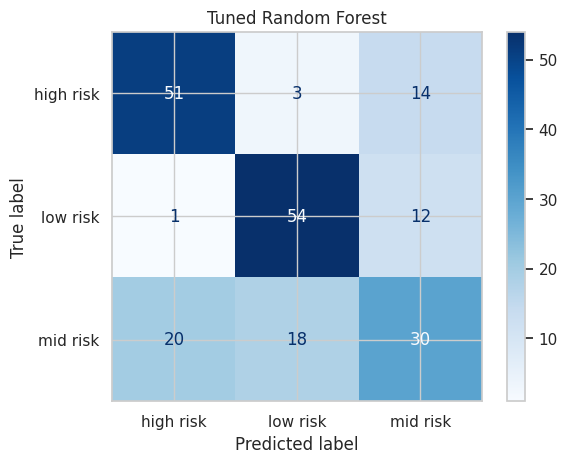


=== Stacking Ensemble ===  macro-F1=0.6274  macro-AUC=0.8358
              precision    recall  f1-score   support

   high risk       0.71      0.75      0.73        68
    low risk       0.67      0.85      0.75        67
    mid risk       0.50      0.34      0.40        68

    accuracy                           0.65       203
   macro avg       0.63      0.65      0.63       203
weighted avg       0.63      0.65      0.63       203



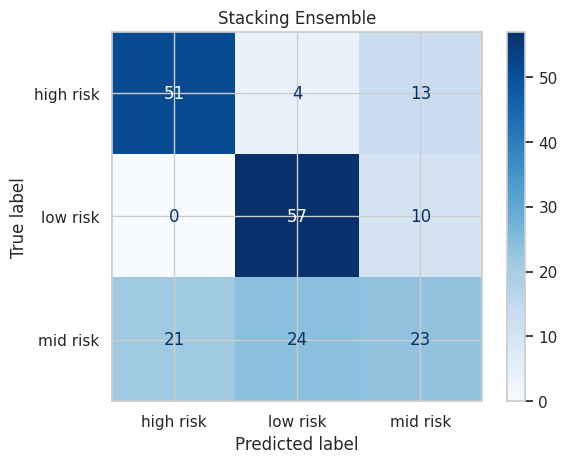


Final model selected: Tuned Random Forest


In [15]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, roc_auc_score

def evaluate(model, tag):
    y_pred = model.predict(X_test_s)
    y_proba = model.predict_proba(X_test_s)
    f1m = f1_score(y_test, y_pred, average="macro")
    auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
    print(f"\n=== {tag} ===  macro-F1={f1m:.4f}  macro-AUC={auc:.4f}")
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=le.classes_, cmap="Blues"
    )
    plt.title(tag)
    plt.show()
    return f1m

f1_rf = evaluate(best_rf, "Tuned Random Forest")
f1_stack = evaluate(stack, "Stacking Ensemble")

final_model, final_name = (stack, "Stacking Ensemble") if f1_stack >= f1_rf else (best_rf, "Tuned Random Forest")
print(f"\nFinal model selected: {final_name}")

## 10. Feature importance (Random Forest)

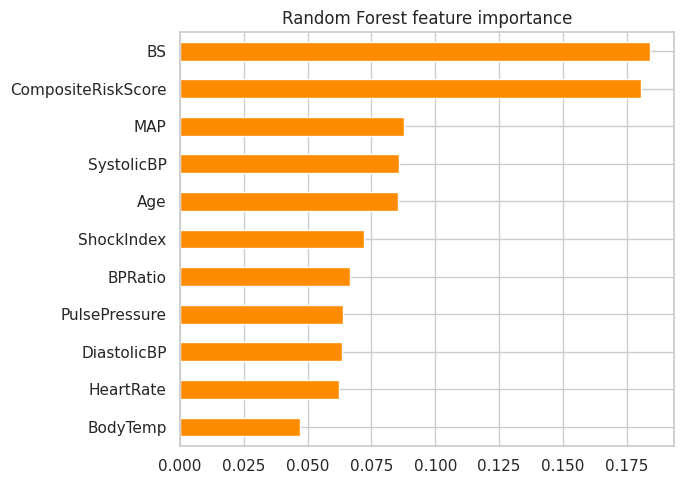

In [16]:
importances = pd.Series(best_rf.feature_importances_, index=BASE_COLS + ENGINEERED_COLS).sort_values()
plt.figure(figsize=(7, 5))
importances.plot(kind="barh", color="darkorange")
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.show()

## 11. Save the final pipeline

In [17]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)
joblib.dump(
    {
        "model": final_model,
        "scaler": scaler,
        "label_encoder": le,
        "feature_columns": BASE_COLS + ENGINEERED_COLS,
        "model_name": final_name,
    },
    "../models/best_model.joblib",
)
print("Saved to ../models/best_model.joblib")

Saved to ../models/best_model.joblib


## Conclusion

- Random Forest / ensemble methods trained on engineered clinical features
  (MAP, Shock Index, Pulse Pressure, BP Ratio, Composite Risk Score) plus
  post-split SMOTE balancing is the combination the literature converges
  on for this problem.
- The **high-risk** class is consistently the easiest to detect (elevated
  BP/blood sugar are strong, unambiguous signals); the **low/mid-risk**
  boundary is the main source of error — worth flagging in any clinical
  deployment so borderline "mid risk" predictions get a second look.
- Swap in the real UCI dataset (`src/get_data.py`) to reproduce the
  85-100% accuracy numbers reported in the published studies.